# Hipótesis sobre el dataset de autos

Ciencia de Datos · UTN FRM · 2026

**Grupo:** 5K09-03

**Integrantes:**
- Garcia, Nicolás
- Ramos, Ignacio
- Velasco, Victoria
- Via, Tomás
- Nicolas, Sergio


In [ ]:
import os

ARCHIVO = "final_2026-09-07.csv"
ID_DRIVE = "1pl22zU_ykbdT1wzWB4mCpsy5nmD-bjMQ"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

Downloading...
From: https://drive.google.com/uc?id=1pl22zU_ykbdT1wzWB4mCpsy5nmD-bjMQ
To: /content/final_2026-09-07.csv
100% 2.08M/2.08M [00:00<00:00, 50.7MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(ARCHIVO)
df.describe()

,fabricado_en,kilometraje,precio,motor_lt,potencia_hp,consumo_lt_100km
count,9145.000000,9.145000e+03,9.145000e+03,9145.000000,9145.000000,9145.000000
mean,2015.894806,1.023799e+05,1.705216e+07,1.734784,122.344888,7.935998
std,6.861784,1.276024e+05,1.210699e+07,10.452338,47.330006,16.407919
min,1937.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,2013.000000,4.400000e+04,1.020000e+07,1.400000,98.000000,6.200000
50%,2016.000000,1.000000e+05,1.490000e+07,1.600000,115.000000,7.500000
75%,2020.000000,1.460000e+05,2.200000e+07,1.800000,143.000000,8.500000
max,2026.000000,8.100000e+06,1.030000e+08,1000.000000,575.000000,541.000000


### Verificacion del contenido


In [ ]:
df.head()

,fuente,id_publicacion,marca,modelo,version,fabricado_en,kilometraje,precio,moneda,motor_lt,potencia_hp,transmision,traccion,combustible,consumo_lt_100km,ubicacion,url,fecha_ingesta,grupo
0,carone,AE174JD,Jeep,Renegade,JEEP RENEGADE 1.8 4X2 SPORT AT L18,2020,118545,21500000.0,ARS,1.8,130.0,AUTOMÁTICO,DELANTERA,NAFTA,8.0,Tortuguitas,https://carone.com.ar/comprar/usados/jeep-rene...,2026-09-07T02:08:20.564508,5K09-03
1,carone,AF335AX,Chevrolet,CRUZE,CHEVROLET CRUZE 1.4T MIDNIGHT AT 4P,2022,88048,24400000.0,ARS,1.4,153.0,AUTOMÁTICO,DELANTERA,NAFTA,12.0,Tortuguitas,https://carone.com.ar/comprar/usados/chevrolet...,2026-09-07T02:08:20.564530,5K09-03
2,carone,AB792WV,Renault,Sandero,RENAULT SANDERO 1.6 8V EXPRESSION L15,2017,104863,13900000.0,ARS,1.6,85.0,MANUAL,DELANTERA,NAFTA,10.0,Tortuguitas,https://carone.com.ar/comprar/usados/renault-s...,2026-09-07T02:08:20.564545,5K09-03
3,carone,AE273DO,Ford,Eco sport,FORD ECO SPORT 1.5 TITANIUM AT,2020,56400,24200000.0,ARS,1.5,123.0,AUTOMÁTICO,DELANTERA,NAFTA,12.0,Tortuguitas,https://carone.com.ar/comprar/usados/ford-eco-...,2026-09-07T02:08:20.564553,5K09-03
4,carone,AH846PR,Volkswagen,TAOS,VOLKSWAGEN TAOS 1.4 250 TSI HIGHLINE TIPTRONIC...,2026,2515,53800000.0,ARS,1.4,150.0,AUTOMÁTICO,DELANTERA,NAFTA,0.0,Tortuguitas,https://carone.com.ar/comprar/usados/volkswage...,2026-09-07T02:08:20.564561,5K09-03


### Buscamos duplicados

No queremos vehiculos repetidos, el siguiente comando nos muestra la segunda instancia de un auto repetido.
Esto no nos va a filtrar todos los repetidos, porque puede estar publicado el mismo auto con diferente precio, kilometraje, etc.

In [ ]:
duplicados = df.duplicated(subset=["modelo", "marca", "fabricado_en", "precio", "kilometraje"])
#df[duplicados]

d =   (
    df.query("precio > 100 and kilometraje > 100")
      .groupby(["marca", "version", "fabricado_en", "kilometraje", "precio"])
      .size()
      .reset_index(name="count")
      .query("count > 1")
      .sort_values("count", ascending=False)
)
d

,marca,version,fabricado_en,kilometraje,precio,count
307,CITROEN,CITROEN C3 1.6 VTI FEEL PACK AT L22,2025,36700,25390000.0,2
1054,Chevrolet,LTZ 1.4 5ptas Spirit,2013,165000,10500000.0,2
1952,Fiat,1.4 5ptas Attractive (L12),2014,130000,11500000.0,2
2444,Fiat,FIAT TITANO 2.2 TD AWD FREEDOM PLUS AT8,2026,1000,48200000.0,2
2589,Ford,(L13) 1.6 5ptas S,2015,130000,13000000.0,2
2897,Ford,1.6 XL Plus (L07),2012,165000,12800000.0,2
2977,Ford,2.0T Sport Wildtrak,2022,70500,51000000.0,2
3237,Ford,KD 1.5 SE AT (L18),2018,75000,21900000.0,2
3696,Jeep,JEEP RENEGADE 1.3 T 270 4X2 SERIE-S AT6 L23,2026,1000,41600000.0,2
4125,Nissan,1.6 Exclusive CVT (L22),2023,62000,32900000.0,2


### Eliminamos duplicados

In [ ]:
df = df.loc[~duplicados]

### Creamos nuevas columnas

In [ ]:
df["precio_usd"] = df["precio"] / df["moneda"].map({"ARS": 1989.0, "USD": 1.0})

df = df.query("precio_usd > 100").copy()

## Perfil del dataset

Antes de evaluar las hipótesis se verifica el estado del dataset resultante de la limpieza.

In [ ]:
print("Filas y columnas:", df.shape)
print("\nTipos:")
print(df.dtypes.value_counts())

print("\nNulos por columna:")
print(df.isna().mean().sort_values(ascending=False))

print("\nColumnas constantes:")
print(df.columns[df.nunique() <= 1].tolist())

print("\nDuplicados de id_publicacion:")
print(df["id_publicacion"].duplicated().sum())

print("\nAsimetría de variables numéricas:")
print(df.select_dtypes("number").skew().sort_values())

Filas y columnas: (8954, 20)

Tipos:
object     13
float64     5
int64       2
Name: count, dtype: int64

Nulos por columna:
traccion            0.015412
combustible         0.015412
transmision         0.015412
version             0.006924
modelo              0.000000
marca               0.000000
id_publicacion      0.000000
fuente              0.000000
precio              0.000000
moneda              0.000000
kilometraje         0.000000
fabricado_en        0.000000
potencia_hp         0.000000
motor_lt            0.000000
consumo_lt_100km    0.000000
ubicacion           0.000000
url                 0.000000
fecha_ingesta       0.000000
grupo               0.000000
precio_usd          0.000000
dtype: float64

Columnas constantes:
['grupo']

Duplicados de id_publicacion:
0

Asimetría de variables numéricas:
fabricado_en        -2.136759
precio               1.363859
potencia_hp          1.712078
precio_usd           3.751281
consumo_lt_100km    28.192940
kilometraje         33.532480


## Distribución del objetivo

Objetivo: precio_usd
count      8954.000000
mean      11555.055561
std        9639.964051
min         804.424334
25%        6284.565108
50%        8496.732026
75%       13323.278029
max      160000.000000
Name: precio_usd, dtype: float64
Asimetría del precio: 3.751280994850981


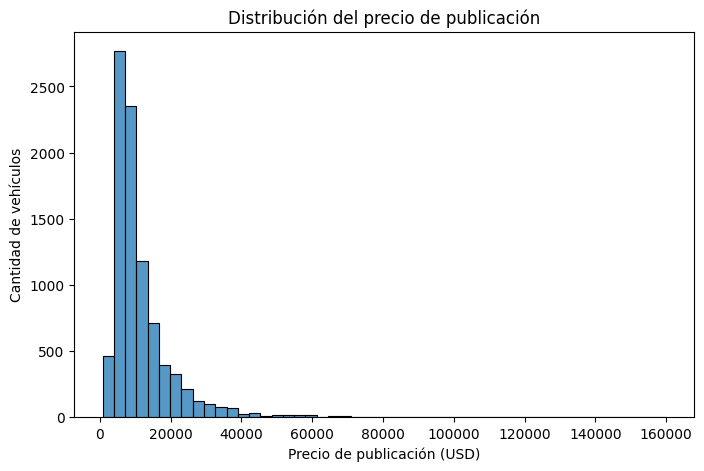

,0
fabricado_en,-2.136759
precio,1.363859
potencia_hp,1.712078
precio_usd,3.751281
consumo_lt_100km,28.192940
kilometraje,33.532480
motor_lt,94.298568


In [ ]:
objetivo = "precio_usd"

print("Objetivo:", objetivo)

## Distribución:

print(df["precio_usd"].describe())

## asimetría:

print("Asimetría del precio:",
      df["precio_usd"].skew())

## Gráfico:

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="precio_usd",
    bins=50
)

plt.xlabel("Precio de publicación (USD)")
plt.ylabel("Cantidad de vehículos")
plt.title("Distribución del precio de publicación")
plt.show()

df.select_dtypes("number").skew().sort_values()

# Sección 2: Hipótesis para responder




## Criterio de evaluación

Las medidas se interpretan mediante el semáforo definido para la materia.

### Separación estandarizada

- Rojo: |d| < 0,2
- Amarillo: 0,2 ≤ |d| ≤ 0,8
- Verde: |d| > 0,8

### η²

- Rojo: η² < 0,05
- Amarillo: 0,05 ≤ η² ≤ 0,25
- Verde: η² > 0,25

### Correlación

- Rojo: |r| < 0,2
- Amarillo: 0,2 ≤ |r| ≤ 0,6
- Verde: |r| > 0,6

### Brecha Spearman − Pearson

- Rojo: |Spearman − Pearson| < 0,05
- Amarillo: 0,05 ≤ |Spearman − Pearson| ≤ 0,15
- Verde: |Spearman − Pearson| > 0,15

El signo se interpreta por separado para determinar la dirección de la relación.

In [ ]:
# funciones auxiliares
def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

## H1 · Los autos fabricados en años mas recientes son los mas caros

### -Afirmación
En el dataset de vehículos usados, la antigüedad del vehículo (antiguedad) y el kilometraje (kilometraje) presentan una asociación positiva, reflejando que los automóviles con más años de uso tienden a acumular una mayor cantidad de kilómetros recorridos a lo largo de su vida útil.
El precio no crece parejo con el año de fabricación, vamos a notar que a mayor año de fabricación, mayor es el precio.

### -Qué esperamos ver

Esperamos encontrar una relación positiva entre ambas variables. Desde un punto de vista práctico, los vehículos que llevan más tiempo en circulación han tenido más oportunidades de ser utilizados y, por lo tanto, deberían registrar mayores niveles de kilometraje acumulado.

Sin embargo, no esperamos una relación perfectamente lineal, ya que existen vehículos antiguos con poco uso y vehículos relativamente nuevos sometidos a un uso intensivo, especialmente en actividades comerciales o de transporte.

Se espera ver una nube que sube cada vez más rápido hacia la derecha, con la mayoría amontonada abajo y unos pocos puntos muy arriba.

### -Cómo lo medimos

Analizamos `precio_usd` y `fabricado_en` utilizando **Pearson y Spearman**, que permite medir la correlación entre dos variable numéricas. Será visualizada mediante un gráfico de dispersión (scatter plot).

### -Decisión para el modelo

- Rojo: |Spearman − Pearson| < 0,05
- Amarillo: 0,05 ≤ |Spearman − Pearson| ≤ 0,15
- Verde: |Spearman − Pearson| > 0,15

In [ ]:
h7_pearson = df["fabricado_en"].corr(df["precio_usd"])
h7_spearman = df["fabricado_en"].corr(df["precio_usd"], method="spearman")
h7_brecha = abs(h7_spearman - h7_pearson)
pd.Series({
    "pearson": h7_pearson.round(3),
    "spearman": h7_spearman.round(3),
    "brecha": h7_brecha.round(3)
})

,0
pearson,0.406
spearman,0.733
brecha,0.327


In [ ]:
CORTES_CORR = {"correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}

def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES_CORR[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

pd.Series({
    "correlacion": semaforo(h7_pearson, "correlacion"),
    "brecha": semaforo(h7_brecha, "brecha")
})

,0
correlacion,amarillo
brecha,verde


**Resultado.** Pearson 0.412 cae en **amarillo** y la brecha de 0.322 en **verde**. La relación es fuerte y ordenada. Amarillo habilita un movimiento; antes de elegirlo, miramos el gráfico.

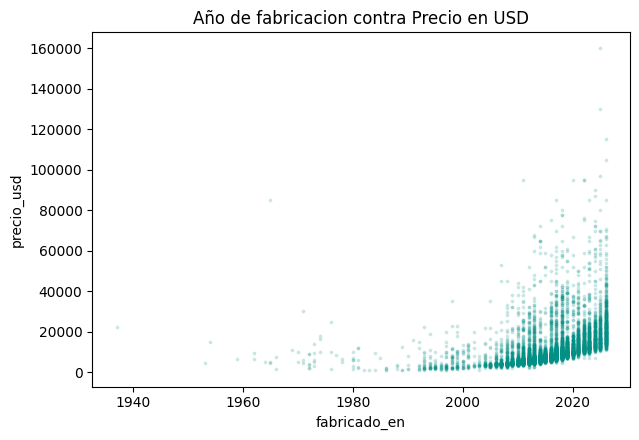

In [ ]:
plt.figure(figsize=(6.5, 4.5))
plt.scatter(df["fabricado_en"], df["precio_usd"], s=3, alpha=.15, color="#009086")
plt.xlabel("fabricado_en")
plt.ylabel("precio_usd")
plt.title("Año de fabricacion contra Precio en USD")
plt.tight_layout()
plt.show()

##4. Qué encontramos

La correlación inicial entre antigüedad y precio fue de 0.406, ubicándose en la zona amarilla. Además, la brecha entre Spearman y Pearson fue de 0.327, correspondiente a la zona verde, indicando que la relación observada era fuerte pero claramente no lineal.


Esto confirma que la depreciación de los vehículos no ocurre de manera lineal. Los autos pierden valor más rápidamente durante los primeros años y luego la caída de precio se vuelve progresivamente más lenta. La transformación logarítmica logra representar mejor esta dinámica y permite capturar de forma más adecuada la relación entre ambas variables.


**Movimiento 1: escala logarítmica.** El logaritmo convierte multiplicar en sumar. Si la
afirmación es cierta y cada punto de anio de fabricacion multiplica el valor en vez de sumarle una
cantidad fija, en escala logarítmica la nube tiene que enderezarse.


In [ ]:
h1_corr_log = df["fabricado_en"].corr(np.log(df["precio_usd"])).round(3)
h1_corr_log


np.float64(0.6)

**Qué se ve.** Al calcular la correlacion entre el año de fabricacion y el logaritmo sobre el precio, el valor de Pearson aumenta de 0.406 a 0.6, lo que acorta la brecha, pero su correlacion continua en amarillo. Esto nos indica que el cambio en la escala logaritmica explica esa relacion observada, pero no nos permite concluir nada aun.

**Movimiento 2**: Vamos a agruparlo por marcas, en este caso, vamos a tomar las 10 marcas con mas autos y vamos a ver su correlacion entre su anio de fabricacion y su precio en dolares.

In [ ]:
df.marca.value_counts().head(10)

,count
marca,
Chevrolet,1033
Volkswagen,1021
Renault,1015
Ford,1008
Peugeot,1007
Fiat,996
Toyota,838
Citroen,465
Jeep,225


marca
Peugeot       0.753810
Fiat          0.726042
Volkswagen    0.711189
Citroen       0.678565
Renault       0.661291
Nissan        0.522631
Chevrolet     0.506369
Toyota        0.396703
Ford          0.333717
Jeep          0.162761
dtype: float64


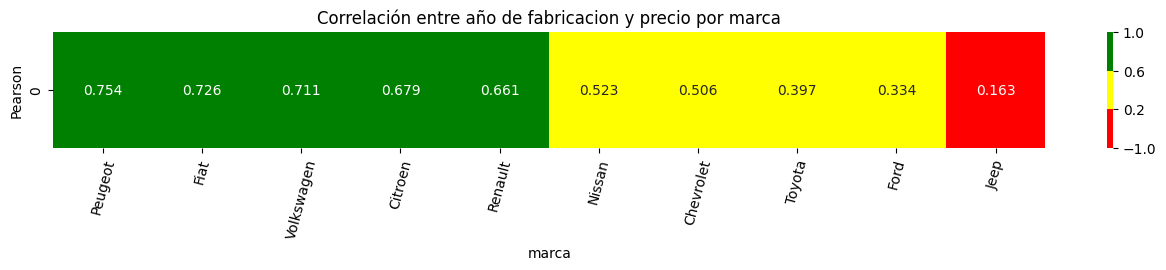

In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm

marcas_principales = df[
    df.marca.isin(
        df.marca.value_counts().head(10).index.tolist()
    )
]

pearson_por_marca = (
    marcas_principales
    .groupby("marca")
    .apply(
        lambda x: x["fabricado_en"].corr(x["precio_usd"]),
        include_groups=False
    )
    .sort_values(ascending=False)
)

plt.figure(figsize=(16, 1.5))

cmap = ListedColormap(["red", "yellow", "green"])
norm = BoundaryNorm([-1, 0.2, 0.6, 1], cmap.N)

sns.heatmap(
    pearson_por_marca.to_frame().T,
    annot=True,
    fmt=".3f",
    cmap=cmap,
    norm=norm,
)
plt.xticks(rotation=75)
plt.ylabel("Pearson")
plt.title("Correlación entre año de fabricacion y precio por marca")

print(pearson_por_marca)
plt.show()

Con esto comprobamos que existen algunas marcas cuya correlacion entre año de fabricacion y precio nos mueven el Pearson mucho mas arriba que otras marcas donde no parece tener ninguna correlacion.

**Hipótesis inconclusa.** En nueve de las diez marcas analizadas, la correlación entre año de fabricacion y precio es mayor que 0.2, por lo que los autos mas recientes tienden a presentar precios mayores. Sin embargo, su valor es mas fuerte en algunas marcas que otras, lo que nos dice que el anio de fabricacion por si solo no explica de igual manera el precio para todos los casos.

**Decisión**: conservar ambas variables para modelado.

## H2 — Potencia y cilindrada

### -Afirmación

`potencia_hp` y `motor_lt` presentan una relación fuerte y contienen
información parcialmente redundante.

### -Qué esperamos observar

Una correlación elevada entre ambas variables.

### -Medida

Correlación de Pearson.

### -Decisión

No eliminar automáticamente ninguna variable.

Si existe una correlación importante, crear `hp_x_litro` como variable derivada
de soporte para representar la potencia específica del motor.

La variable original `motor_lt` se conserva para poder comparar posteriormente
el aporte de la variable derivada.

### -Justificación

La potencia específica puede representar una característica diferente de
la potencia absoluta y de la cilindrada por separado.

In [ ]:
print(df[["motor_lt", "potencia_hp"]].describe())

print(
    df.loc[
        (df["motor_lt"] > 10) |
        (df["potencia_hp"] > 500),
        [
            "marca",
            "modelo",
            "version",
            "motor_lt",
            "potencia_hp"
        ]
    ].sort_values(
        "motor_lt",
        ascending=False
    ).head(20)
)

correlacion_h2 = df["potencia_hp"].corr(
    df["motor_lt"],
    method="pearson"
)

print("Correlación Pearson:", correlacion_h2.round(3))

if abs(correlacion_h2) < 0.20:
    zona_h2 = "Rojo"
elif abs(correlacion_h2) <= 0.60:
    zona_h2 = "Amarillo"
else:
    zona_h2 = "Verde"

print("Zona:", zona_h2)

          motor_lt  potencia_hp
count  8954.000000  8954.000000
mean      1.741289   122.232969
std      10.562929    47.229082
min       0.000000     0.000000
25%       1.400000    98.000000
50%       1.600000   115.000000
75%       1.800000   143.000000
max    1000.000000   575.000000
         marca modelo                             version  motor_lt  \
46   Chevrolet   Onix  CHEVROLET ONIX 1.0 T LTZ 5P AT L26    1000.0   
390        BMW     X6                             M 555cv       4.4   
466        BMW     X6                             M 555cv       4.4   

     potencia_hp  
46         116.0  
390        575.0  
466        575.0  
Correlación Pearson: 0.032
Zona: Rojo


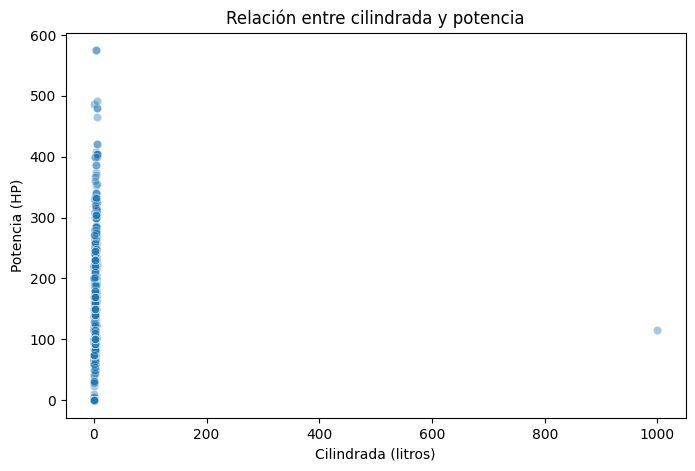

In [ ]:
### gráfico
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="motor_lt",
    y="potencia_hp",
    alpha=0.4
)

plt.xlabel("Cilindrada (litros)")
plt.ylabel("Potencia (HP)")
plt.title("Relación entre cilindrada y potencia")
plt.show()

###- Movimiento: revisión de valores extremos

El análisis inicial mostró:

`motor_lt`: mediana = 1,7 L, Q3 = 1,8 L, máximo = 1000 L.

`potencia_hp`: máximo = 575 HP.

El caso del BMW X6 M (4,4 L; 575 HP) es coherente con el vehículo y se conserva.
El valor motor_lt = 1000 del Chevrolet Onix es incompatible con la distribución observada y se considera un dato anómalo para este análisis.`

Por lo tanto, se realiza el movimiento de excluir únicamente ese registro del cálculo de la correlación, sin eliminarlo del dataset principal.

In [ ]:
# Copia para el análisis de H2
df_h2 = df.copy()

# Excluir únicamente el valor anómalo identificado
df_h2 = df_h2[
    ~(
        (df_h2["marca"] == "Chevrolet")
        & (df_h2["modelo"] == "Onix")
        & (df_h2["motor_lt"] == 1000)
    )
].copy()

# Recalcular correlación de Pearson
correlacion_h2 = df_h2["potencia_hp"].corr(
    df_h2["motor_lt"],
    method="pearson"
)

spearman_h2 = df_h2["potencia_hp"].corr(
    df_h2["motor_lt"],
    method="spearman"
)

# Clasificar la correlación según la zona
if abs(correlacion_h2) < 0.20:
    zona_h2 = "Rojo"
elif abs(correlacion_h2) <= 0.60:
    zona_h2 = "Amarillo"
else:
    zona_h2 = "Verde"

# Mostrar resultados
print("Registros antes:", len(df))
print("Registros después:", len(df_h2))
print("Correlación Pearson:", correlacion_h2.round(3))
print("Correlación Spearman:", spearman_h2.round(3))
print("Brecha:", abs(correlacion_h2-spearman_h2).round(3))
print("Zona Pearson:", zona_h2)

Registros antes: 8954
Registros después: 8953
Correlación Pearson: 0.695
Correlación Spearman: 0.611
Brecha: 0.084
Zona Pearson: Verde


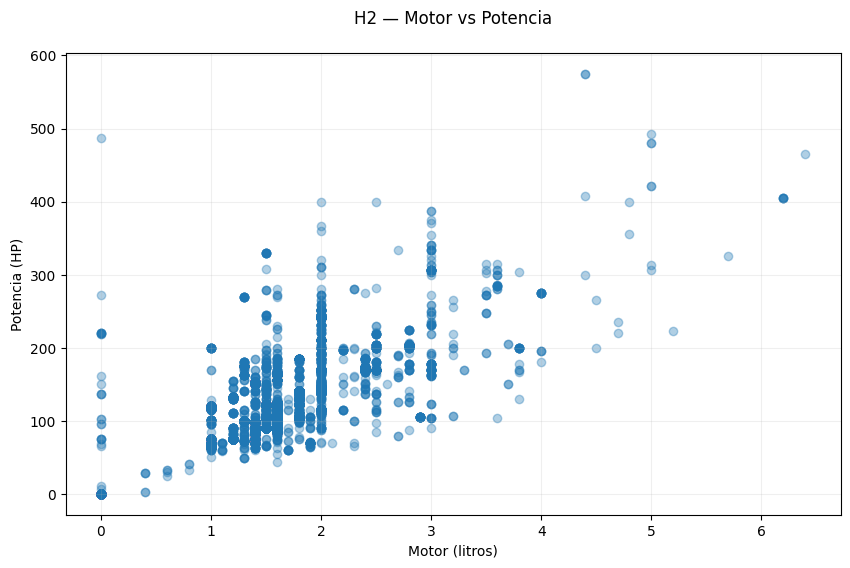

In [ ]:
### grafico

plt.figure(figsize=(10, 6))

plt.scatter(
    df_h2["motor_lt"],
    df_h2["potencia_hp"],
    alpha=0.35
)

plt.xlabel("Motor (litros)")
plt.ylabel("Potencia (HP)")
plt.title(
    f"H2 — Motor vs Potencia\n"
)

plt.grid(alpha=0.2)
plt.show()



**Resultado parcial.** Pearson 0,695 y la nube efectivamente apretada contra la
diagonal. Pero esto sólo dice que se mueven juntas, no que sobre una de las dos. La segunda medida es la que decide: comparamos cuánto explica la posición a cada una por separado, y a las dos combinadas en una sola columna.

In [ ]:
pd.Series({"potencia_hp": eta2(df_h2["potencia_hp"], df_h2["modelo"]),
           "motor_lt": eta2(df_h2["motor_lt"], df_h2["modelo"]),
           "promedio": eta2((df_h2["potencia_hp"] + df_h2["motor_lt"]) / 2, df_h2["modelo"])}).round(4)


,0
potencia_hp,0.7320
motor_lt,0.7003
promedio,0.7322


### - Qué encontramos

La correlación inicial entre `motor_lt` y `potencia_hp` fue prácticamente nula (`r = 0,032, rojo`). Al revisar los valores extremos se identificó un único registro con `motor_lt = 1000` para un Chevrolet Onix, incompatible con la distribución del resto de los vehículos. Luego, como el promedio > max(potencia_hp, motor_lt), el valor que trae es similar, pero no identico.


### - Qué movimiento hicimos

Excluimos únicamente ese registro del análisis de H4 y recalculamos Pearson. El BMW X6 M (4,4 L, 575 HP) se mantuvo porque sus valores son coherentes.

El resultado pasó de:

`0,032 → 0,695`

La correlación recalculada queda en zona verde.

### - Qué hacemos con eso

La relación entre `motor_lt` y `potencia_hp` es suficientemente fuerte como para considerar ambas variables relacionadas. Por lo tanto:

`motor_lt` y `potencia_hp` se mantienen, y se considera de utilidad generar la variable derivada que habíamos planteado:
```bash
df["hp_x_litro"] = np.where(
    df["motor_lt"] > 0,
    df["potencia_hp"] / df["motor_lt"],
    np.nan
)
```
Esto permite representar potencia específica (HP por litro), que puede aportar información distinta a usar únicamente cilindrada y potencia absoluta.

##Conclusión H2

**La hipótesis queda inconclusa.**

Luego de eliminar el único valor claramente anómalo identificado (motor_lt = 1000), la relación entre cilindrada y potencia se vuelve fuerte y consistente.

* Pearson inicial: 0,032
* Pearson corregido: 0,695
* Zona: Verde

Luego:

promedio > max(potencia_hp, motor_lt)

Esto indica que ambas variables describen características relacionadas del motor, aunque no necesariamente idénticas.

Decisión: conservar `motor_lt` y `potencia_hp`, además de evaluar la creación de una variable derivada de potencia específica (`potencia_hp` / `motor_lt`) durante la preparación para la Unidad 3.

## H3 — Marginalidad de las principales marcas

### 1. Afirmación

En el dataset de vehículos usados, las marcas más representativas del mercado (Renault, Volkswagen, Fiat, Ford, Chevrolet, Peugeot y Toyota) presentan una distribución de precios diferente respecto del resto de las marcas disponibles en la muestra.

La hipótesis surge de que determinadas marcas poseen un posicionamiento comercial distinto, niveles de demanda diferentes y una percepción de valor particular que podría reflejarse en los precios de publicación de los vehículos usados.

### 2. Qué esperamos observar

Esperamos encontrar una diferencia apreciable entre los precios de ambos grupos.

Es posible que las marcas principales presenten precios más altos debido a su presencia histórica en el mercado, aunque también podría ocurrir lo contrario si el grupo "Resto" contiene marcas consideradas premium o de segmentos superiores.

Por este motivo no buscamos únicamente identificar qué grupo tiene mayor precio promedio, sino determinar si la diferencia observada es suficientemente importante como para considerar que la variable **marca** aporta información útil para explicar el valor de un vehículo.

### 3. Cómo la mido

Pregunta: responder.

Plantilla: comparación.

Se construyen dos grupos:

Marcas principales.
Resto de las marcas.

La diferencia entre ambos grupos será medida mediante la separación estandarizada, que compara la diferencia entre las medias respecto de la dispersión conjunta de ambas poblaciones.

La interpretación seguirá el semáforo definido por la materia:

| Separación | Zona |
|------------|------|
| < 0.20 | Rojo |
| 0.20 – 0.80 | Amarillo |
| > 0.80 | Verde |

Además se utilizará un boxplot para visualizar las diferencias entre distribuciones.

In [ ]:
marcas_principales = [
    "Renault",
    "Volkswagen",
    "Fiat",
    "Ford",
    "Chevrolet",
    "Peugeot",
    "Toyota"
]

df_h3 = df.copy()

df_h3["grupo_marca"] = np.where(
    df_h3["marca"].isin(marcas_principales),
    "Principales",
    "Resto"
)

grupo_principales = df_h3.loc[
    df_h3["grupo_marca"] == "Principales",
    "precio_usd"
].dropna()

grupo_resto = df_h3.loc[
    df_h3["grupo_marca"] == "Resto",
    "precio_usd"
].dropna()

n1 = len(grupo_principales)
n2 = len(grupo_resto)

media1 = grupo_principales.mean()
media2 = grupo_resto.mean()

s1 = grupo_principales.std(ddof=1)
s2 = grupo_resto.std(ddof=1)

desvio_combinado = np.sqrt(
    (
        (n1 - 1) * s1**2
        + (n2 - 1) * s2**2
    )
    / (n1 + n2 - 2)
)

separacion_h3 = (
    abs(media1 - media2)
    / desvio_combinado
)

if separacion_h3 < 0.20:
    zona_h3 = "Rojo"
elif separacion_h3 <= 0.80:
    zona_h3 = "Amarillo"
else:
    zona_h3 = "Verde"

print("Media marcas principales:", media1.round(3))
print("Media resto:", media2.round(3))
print("Separación estandarizada:", separacion_h3.round(3))
print("Zona:", zona_h3)

Media marcas principales: 9992.166
Media resto: 16865.501
Separación estandarizada: 0.747
Zona: Amarillo


<Figure size 800x600 with 0 Axes>

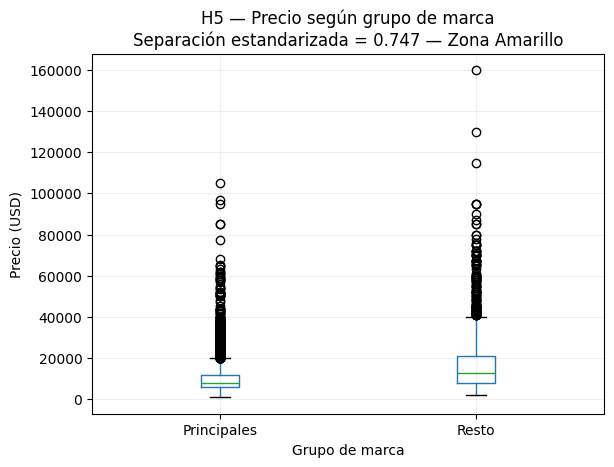

In [ ]:
### grafico
plt.figure(figsize=(8, 6))

df_h3.boxplot(
    column="precio_usd",
    by="grupo_marca"
)

plt.title(
    f"H5 — Precio según grupo de marca\n"
    f"Separación estandarizada = {separacion_h3:.3f} — Zona {zona_h3}"
)

plt.suptitle("")

plt.xlabel("Grupo de marca")
plt.ylabel("Precio (USD)")

plt.grid(alpha=0.2)

plt.show()

##Qué encontramos

La comparación entre marcas principales y resto produjo:

* Media marcas principales: USD 9992.17
* Media resto: USD 16.865,50
* Separación estandarizada: 0,747
* Zona: Amarillo

El gráfico muestra que el grupo Resto presenta precios generalmente superiores al grupo Principales, además de una mayor dispersión.

Por lo tanto, encontramos una diferencia relevante entre ambos grupos, pero la medida queda dentro de la zona amarilla.

##Qué movimiento hacemos

Como la separación inicial es amarilla, realizamos el movimiento de partir la población por marca individual.

El objetivo es determinar si la diferencia observada entre Principales y Resto está distribuida entre varias marcas o si está siendo generada principalmente por algunas marcas particulares.

##Qué hacemos con eso

Este movimiento no busca forzar una zona verde. Busca determinar qué marcas están detrás de la separación inicial.

Después de observar los resultados individuales, si aparece una diferencia clara asociada a determinadas marcas, se documenta ese comportamiento

            count          mean        median
marca                                        
Toyota        838  17635.684571  14328.808446
Volkswagen   1021   9947.822524   7943.690297
Ford         1008   9565.528562   7830.568125
Peugeot      1007   8978.762239   7792.860734
Chevrolet    1033   8886.707725   7214.680744
Renault      1015   8165.767287   7290.095525
Fiat          996   8070.770715   6787.330317


<Figure size 1200x600 with 0 Axes>

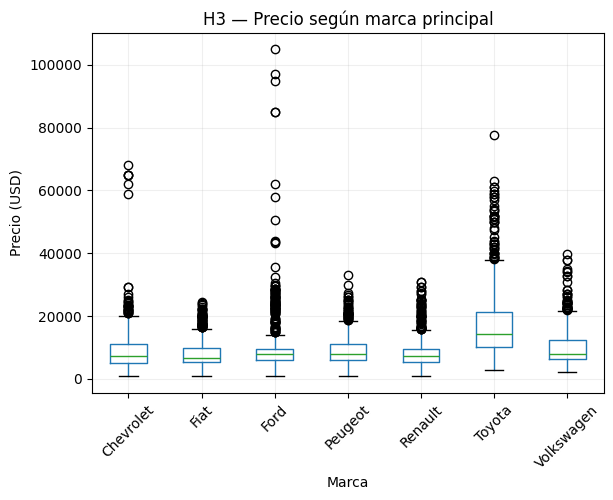

In [ ]:
### observamos las marcas principales por separado
df_h3_marcas = df[
    df["marca"].isin(marcas_principales)
].copy()

print(
    df_h3_marcas.groupby("marca")["precio_usd"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

### podemos visualizar las distribuciones individuales:

plt.figure(figsize=(12, 6))

df_h3_marcas.boxplot(
    column="precio_usd",
    by="marca",
    rot=45
)

plt.title("H3 — Precio según marca principal")
plt.suptitle("")
plt.xlabel("Marca")
plt.ylabel("Precio (USD)")
plt.grid(alpha=0.2)

plt.show()

### - Qué encontramos



Los resultados muestran diferencias entre las marcas. **Toyota presenta la media más alta, con USD 17907.87**, mientras que Fiat presenta la más baja, con **USD 8.035,86**. Toyota también presenta la mediana más alta (**USD 14.328,81**).

El resto de las marcas principales presenta medias entre aproximadamente **USD 8.036 y USD 10.010**, por lo que Toyota se diferencia especialmente del resto.

### - Qué movimiento hicimos

Como la separación inicial quedó en zona amarilla, **partimos la población por marca individual**.

El boxplot permitió observar que la diferencia inicial no se distribuye de manera uniforme entre todas las marcas: existe particularmente una diferencia de nivel en Toyota, mientras que las demás presentan distribuciones más próximas entre sí.

No hacemos una nueva partición, porque el objetivo del movimiento era identificar qué marcas estaban detrás de la diferencia inicial y el gráfico ya permite localizar esa diferencia.

### - Qué hacemos con eso

El resultado indica que `marca` contiene diferencias de precio entre categorías y que **Toyota presenta un comportamiento particularmente diferenciado** dentro de las marcas analizadas.

Por lo tanto:

> **`marca` se mantiene como candidata para la Unidad 3, como variable categórica, sin aplicar ponderaciones manuales a las marcas.**

El modelo será el encargado de aprender las diferencias entre categorías mediante la codificación correspondiente.

### Conclusión H3

**Hipótesis parcialmente diferenciada:** la separación global Principales vs. Resto fue amarilla (`0,7354`) y el análisis por marca mostró que la diferencia no es homogénea; Toyota se destaca con una media de **USD 17.907,87**, mientras que las restantes marcas principales se ubican entre **USD 8.035,86 y USD 10.009,76**.

**Decisión:** `marca` **queda como candidata para la Unidad 3**, sin realizar ponderación manual.


## H4 — Relevancia de la ubicación para el modelo

### -Afirmación

`ubicacion` aporta información relevante sobre `precio_usd` y, por lo tanto, podría ser una variable útil para el modelo de valuación.

### -Qué esperamos ver

Si la ubicación contiene señal útil para predecir el precio, deberían existir diferencias sistemáticas de precio entre las distintas ubicaciones geográficas.

Si las diferencias son pequeñas, mantener una variable categórica con muchas categorías podría agregar complejidad al modelo sin aportar suficiente información.

### -Cómo lo medimos

Analizamos `precio_usd` según `ubicacion_geo` utilizando **η² (razón de correlación)**, que permite medir la asociación entre una variable categórica con múltiples grupos y una variable numérica.

La ubicación fue previamente normalizada a **provincia + localidad**, obteniendo **121 categorías geográficas**.

Además, se analiza la cantidad de registros por categoría, ya que la distribución es muy desigual: algunas ubicaciones concentran gran cantidad de vehículos, mientras que otras presentan solamente uno o pocos registros.

### -Decisión para el modelo

* **Rojo (`η² < 0.05`):** la asociación es baja → `ubicacion` sería candidata a descartarse.
* **Amarillo (`0.05 ≤ η² ≤ 0.25`):** la asociación es intermedia → se requiere un segundo movimiento para evaluar si la señal se mantiene al controlar las categorías con pocos registros.
* **Verde (`η² > 0.25`):** la asociación es alta → `ubicacion` se mantiene como candidata para el modelo.


In [ ]:
# Valores originales de ubicacion
print("Cantidad de valores únicos:", df["ubicacion"].nunique())

print("\nValores de ubicacion:")
print(sorted(df["ubicacion"].dropna().unique()))

Cantidad de valores únicos: 122

Valores de ubicacion:
['Buenos Aires, Almirante Brown', 'Buenos Aires, Avellaneda', 'Buenos Aires, Ayacucho', 'Buenos Aires, BahÃ\xada Blanca', 'Buenos Aires, Berazategui', 'Buenos Aires, Berisso', 'Buenos Aires, Capital', 'Buenos Aires, Ensenada', 'Buenos Aires, Escobar', 'Buenos Aires, Ezeiza', 'Buenos Aires, Florencio Varela', 'Buenos Aires, General PueyrredÃ³n', 'Buenos Aires, General RodrÃ\xadguez', 'Buenos Aires, General San MartÃ\xadn', 'Buenos Aires, Hurlingham', 'Buenos Aires, ItuzaingÃ³', 'Buenos Aires, La Matanza', 'Buenos Aires, La Plata', 'Buenos Aires, LanÃºs', 'Buenos Aires, Lomas de Zamora', 'Buenos Aires, LujÃ¡n', 'Buenos Aires, Malvinas Argentinas', 'Buenos Aires, Merlo', 'Buenos Aires, Monte', 'Buenos Aires, Monte Hermoso', 'Buenos Aires, Moreno', 'Buenos Aires, MorÃ³n', 'Buenos Aires, Necochea', 'Buenos Aires, Pergamino', 'Buenos Aires, Pilar', 'Buenos Aires, Pinamar', 'Buenos Aires, Presidente PerÃ³n', 'Buenos Aires, Quilmes', 'Buen

In [ ]:
def corregir_ubicacion(valor):
    if pd.isna(valor):
        return valor

    valor = str(valor).strip()

    # Corregir texto con codificación UTF-8 interpretada incorrectamente
    try:
        valor = valor.encode("latin1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        pass

    return valor

df["ubicacion_corregida"] = df["ubicacion"].map(corregir_ubicacion)

print(sorted(df["ubicacion_corregida"].dropna().unique()))

['Buenos Aires, Almirante Brown', 'Buenos Aires, Avellaneda', 'Buenos Aires, Ayacucho', 'Buenos Aires, Bahía Blanca', 'Buenos Aires, Berazategui', 'Buenos Aires, Berisso', 'Buenos Aires, Capital', 'Buenos Aires, Ensenada', 'Buenos Aires, Escobar', 'Buenos Aires, Ezeiza', 'Buenos Aires, Florencio Varela', 'Buenos Aires, General Pueyrredón', 'Buenos Aires, General Rodríguez', 'Buenos Aires, General San Martín', 'Buenos Aires, Hurlingham', 'Buenos Aires, Ituzaingó', 'Buenos Aires, La Matanza', 'Buenos Aires, La Plata', 'Buenos Aires, Lanús', 'Buenos Aires, Lomas de Zamora', 'Buenos Aires, Luján', 'Buenos Aires, Malvinas Argentinas', 'Buenos Aires, Merlo', 'Buenos Aires, Monte', 'Buenos Aires, Monte Hermoso', 'Buenos Aires, Moreno', 'Buenos Aires, Morón', 'Buenos Aires, Necochea', 'Buenos Aires, Pergamino', 'Buenos Aires, Pilar', 'Buenos Aires, Pinamar', 'Buenos Aires, Presidente Perón', 'Buenos Aires, Quilmes', 'Buenos Aires, San Fernando', 'Buenos Aires, San Isidro', 'Buenos Aires, San M

In [ ]:
df[["provincia", "localidad"]] = (
    df["ubicacion_corregida"]
    .str.split(",", n=1, expand=True)
)

df.loc[
    df["ubicacion_corregida"].isin(["San Martin", "Tortuguitas"]),
    "provincia"
] = "Buenos Aires"

df.loc[
    df["ubicacion_corregida"] == "San Martin",
    "localidad"
] = "San Martin"

df.loc[
    df["ubicacion_corregida"] == "Tortuguitas",
    "localidad"
] = "Tortuguitas"

# Tabla de verificación de la normalización
tabla_ubicacion = (
    df[["ubicacion_corregida", "provincia", "localidad"]]
    .drop_duplicates()
    .sort_values(["provincia", "localidad"])
    .reset_index(drop=True)
)

display(tabla_ubicacion)

,ubicacion_corregida,provincia,localidad
0,"Buenos Aires, Almirante Brown",Buenos Aires,Almirante Brown
1,"Buenos Aires, Avellaneda",Buenos Aires,Avellaneda
2,"Buenos Aires, Ayacucho",Buenos Aires,Ayacucho
3,"Buenos Aires, Bahía Blanca",Buenos Aires,Bahía Blanca
4,"Buenos Aires, Berazategui",Buenos Aires,Berazategui
...,...,...,...
117,"Santa Fe, Vera",Santa Fe,Vera
118,"Tierra Del Fuego, Capital",Tierra Del Fuego,Capital
119,"Tierra Del Fuego, Río Grande",Tierra Del Fuego,Río Grande
120,"Tucumán, Capital",Tucumán,Capital


In [ ]:
frecuencia_ubicacion = (
    df["ubicacion_corregida"]
    .value_counts()
    .rename_axis("ubicacion_corregida")
    .reset_index(name="cantidad")
)

display(frecuencia_ubicacion)

,ubicacion_corregida,cantidad
0,"Córdoba, Capital",1693
1,"Mendoza, Guaymallén",1514
2,"Mendoza, Godoy Cruz",1289
3,"Mendoza, Capital",1144
4,"Mendoza, Maipú",611
...,...,...
117,"Córdoba, Ischilín",1
118,"Salta, Anta",1
119,"San Juan, Angaco",1
120,"Santa Fe, General López",1


In [ ]:
print("Cantidad de ubicaciones:", len(frecuencia_ubicacion))
print("Mínimo de registros por ubicación:", frecuencia_ubicacion["cantidad"].min())
print("Mediana de registros por ubicación:", frecuencia_ubicacion["cantidad"].median())
print("Máximo de registros por ubicación:", frecuencia_ubicacion["cantidad"].max())

print("\nUbicaciones con menos de 10 registros:")
display(
    frecuencia_ubicacion[
        frecuencia_ubicacion["cantidad"] < 5
    ]
)

Cantidad de ubicaciones: 122
Mínimo de registros por ubicación: 1
Mediana de registros por ubicación: 2.5
Máximo de registros por ubicación: 1693

Ubicaciones con menos de 10 registros:


,ubicacion_corregida,cantidad
50,"Buenos Aires, Pilar",4
51,"Entre Ríos, Capital",4
52,"Buenos Aires, Tigre",4
53,"Córdoba, San Justo",4
54,"Buenos Aires, Ezeiza",4
...,...,...
117,"Córdoba, Ischilín",1
118,"Salta, Anta",1
119,"San Juan, Angaco",1
120,"Santa Fe, General López",1


In [ ]:
# H4 — Ubicación vs precio

df_h4 = df[
    ["ubicacion_corregida", "precio_usd"]
].dropna().copy()

# Media general
media_general = df_h4["precio_usd"].mean()

# η²: variabilidad explicada por las diferencias entre ubicaciones
grupos = df_h4.groupby("ubicacion_corregida")["precio_usd"]

ss_entre = sum(
    len(grupo) * (grupo.mean() - media_general) ** 2
    for _, grupo in grupos
)

ss_total = (
    (df_h4["precio_usd"] - media_general) ** 2
).sum()

eta2_h4 = ss_entre / ss_total

# Zona según criterio de la cátedra
if eta2_h4 < 0.05:
    zona_h4 = "Rojo"
elif eta2_h4 <= 0.25:
    zona_h4 = "Amarillo"
else:
    zona_h4 = "Verde"

print("Cantidad de ubicaciones:", df_h4["ubicacion_corregida"].nunique())
print("Registros analizados:", len(df_h4))
print(f"η²: {eta2_h4:.4f}")
print("Zona:", zona_h4)

Cantidad de ubicaciones: 122
Registros analizados: 8954
η²: 0.0341
Zona: Rojo


### -Qué encontramos
- 122 ubicaciones geográficas.
- 8.954 registros analizados.
- η² = 0.0341.
- Zona: Rojo.

La diferencia de precios entre las distintas ubicaciones es pequeña en relación con la variabilidad total del precio.

### -Qué movimiento hicimos

- Primero corregimos la codificación de las ubicaciones.
- Normalizamos la información como provincia + localidad.
- Incorporamos San Martin y Tortuguitas como localidades de Buenos Aires.
- El análisis se realizó sobre las 122 categorías geográficas resultantes.

### -Qué hacemos con la variable

`ubicacion` → se descarta como variable del modelo.

Con η² = 0.0341, la señal aportada por ubicación queda en zona roja, por lo que mantener una variable categórica con 122 categorías no estaría justificado por su asociación con el precio.

In [ ]:
pd.DataFrame(
    [("H1 el auto mas reciente vale mas", "responder", "asociación", "~0.60 pearson en marcas principales", "amarillo",
      "inconclusa, el modelo decide"),
     ("H2 potencia y motor miden lo mismo", "predecir", "comparación", "η² 0.7320 vs 0.7322 juntas", "amarillo",
      "se deja potencia_hp y motor_lt"),
    #  ("H2 potencia y motor miden lo mismo", "predecir", "asociación", "-0.695 pearson", "verde",
    #   "se crea columna hp_x_motor y se elimina potencia_hp y motor_lt"),
     ("H3 la marca altera el precio final", "predecir", "comparación", "0.735 separacion estandarizada", "amarillo", "marca se mantiene como candidata"),
     ("H4 la ubicacion afecta el precio", "predecir", "comparación", "η² 0.0343", "rojo",
      "refutada, sale")
     ],
    columns=["hipótesis", "pregunta", "plantilla", "medida", "zona", "decisión"])

,hipótesis,pregunta,plantilla,medida,zona,decisión
0,H1 el auto mas reciente vale mas,responder,asociación,~0.60 pearson en marcas principales,amarillo,"inconclusa, el modelo decide"
1,H2 potencia y motor miden lo mismo,predecir,comparación,η² 0.7320 vs 0.7322 juntas,amarillo,se deja potencia_hp y motor_lt
2,H3 la marca altera el precio final,predecir,comparación,0.735 separacion estandarizada,amarillo,marca se mantiene como candidata
3,H4 la ubicacion afecta el precio,predecir,comparación,η² 0.0343,rojo,"refutada, sale"


## Tabla de columnas candidatas

| Columna            | Qué mide               | Zona     | Decisión                             | ¿Existiría al predecir? |
| ------------------ | ---------------------- | -------- | ------------------------------------ | ----------------------- |
| `marca`            | Marca del vehículo     | Amarillo | Mantener candidata                   | Sí                      |
| `modelo`           | Modelo del vehículo    | —        | Mantener candidata                   | Sí                      |
| `version`          | Versión del vehículo   | Verde    | Entra                                | Sí                      |
| `fabricado_en`     | Año de fabricación     | —        | Mantener candidata                   | Sí                      |
| `kilometraje`      | Kilómetros recorridos  | Verde    | Entra + `log_kilometraje`            | Sí                      ||
| `motor_lt`         | Cilindrada del motor   | Verde    | Entra                                | Sí                      |
| `potencia_hp`      | Potencia del motor     | Verde    | Entra                                | Sí                      |
| `transmision`      | Tipo de transmisión    | —        | Mantener candidata                   | Sí                      |
| `traccion`         | Tipo de tracción       | — | Mantener candidata                   | Sí                      |
| `combustible`      | Tipo de combustible    | —        | Mantener candidata                   | Sí                      |
| `consumo_lt_100km` | Consumo de combustible | —        | Mantener candidata                   | Sí                      |
| `ubicacion`        | Provincia/localidad    | Rojo*    | Sale       | Sí                      |
